# Model 3: TextCNN

**Model 3 of 7** in the NLP Sentiment Benchmark (Part A).

This notebook is **self-contained** — upload it to Kaggle as-is, add a GPU accelerator (T4 x1 or x2), and run all cells top to bottom. No other files needed.

At the end it saves the trained model + tokenizer + MLflow logs to `/kaggle/working/` — download those before your Kaggle session expires.

**Architecture idea:** slide several convolution filters of different widths (2,3,4,5 words) over the headline to pick up local n-gram patterns like *"raises repo rate"* or *"record profit"*, then keep only the strongest signal per filter (max pooling).

In [1]:
# Install the few packages Kaggle doesn't ship by default.
# torch / pandas / numpy / matplotlib / scikit-learn are already on Kaggle images.
!pip install -q mlflow seaborn

In [2]:
import os
import re
import ast
import time
import random
import pickle
import logging
from collections import Counter
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt   # uses Jupyter's inline backend on Kaggle — plots render in the notebook
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import mlflow

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
log = logging.getLogger(__name__)

/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# ══════════════════════════════════════════════════════════════
# CONFIG — every constant this notebook needs lives here.
# Change a value once, it affects the whole notebook.
# ══════════════════════════════════════════════════════════════
LABEL2ID = {"positive": 0, "neutral": 1, "negative": 2}
ID2LABEL = {0: "positive", 1: "neutral", 2: "negative"}
NUM_LABELS = 3

VOCAB_SIZE = 30_000     # top-N most frequent words kept in the tokenizer
MAX_LENGTH = 128        # every headline is padded/truncated to this many tokens
PAD_TOKEN, UNK_TOKEN = "<PAD>", "<UNK>"
PAD_IDX, UNK_IDX = 0, 1

SEED = 42
BATCH_SIZE = 64
NUM_EPOCHS = 15
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.01
PATIENCE = 3            # early-stopping patience, measured on val F1-weighted

TEST_SIZE = 0.15        # fraction of full data held out as test
VAL_SIZE = 0.10         # fraction of full data held out as val

MLFLOW_EXPERIMENT = "IndianFinSentiment"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# Works whether you're on Kaggle or running this locally.
BASE_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
RESULTS_DIR = os.path.join(BASE_DIR, "results")
MODELS_DIR = os.path.join(BASE_DIR, "saved_models")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# MLflow 3.x defaults to a SQLite-backed store (metrics/params live INSIDE
# mlflow.db, not as flat files) unless it finds existing file-store data.
# We pin the db to a known path so it's easy to find and download afterwards.
mlflow.set_tracking_uri(f"sqlite:///{os.path.join(BASE_DIR, 'mlflow.db')}")

Using device: cpu


## 1. Load data

**Dataset: SEntFiN-v1.1** — 10,753 Indian financial news headlines with entity-level sentiment.

On Kaggle: click **Add Data** and upload/attach `SEntFiN-v1.1.csv` as a dataset input before running this notebook.
Locally: this reads from `../data/raw/SEntFiN-v1.1.csv`.

In [4]:
# ══════════════════════════════════════════════════════════════
# DATA LOADING — SEntFiN-v1.1 (Indian financial headlines, entity-level sentiment)
# ══════════════════════════════════════════════════════════════

def resolve_sentifin_path() -> str:
    candidates = ["../data/raw/SEntFiN-v1.1.csv", "../data/SEntFiN-v1.1.csv"]
    if os.path.isdir("/kaggle/input"):
        for root, _, files in os.walk("/kaggle/input"):
            for f in files:
                if f == "SEntFiN-v1.1.csv":
                    candidates.insert(0, os.path.join(root, f))
    for path in candidates:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(
        "SEntFiN-v1.1.csv not found. On Kaggle: Add Data -> upload SEntFiN-v1.1.csv as a "
        "dataset and attach it to this notebook. Locally: place it at data/raw/SEntFiN-v1.1.csv."
    )


def load_sentifin() -> pd.DataFrame:
    """
    SEntFiN-v1.1 — 10,753 Indian financial headlines with entity-level sentiment,
    e.g. Decisions = {"SpiceJet": "neutral"}. ~26% of headlines mention >1 entity.
    Since this notebook classifies a whole headline as one label (not entity-aware),
    we keep headlines where every entity shares one sentiment (trivially true for
    single-entity headlines) and drop the ~11.5% where entities disagree — those are
    ambiguous for a single-label classifier.
    """
    log.info("Loading SEntFiN-v1.1...")
    raw = pd.read_csv(resolve_sentifin_path())

    texts, labels, n_entities = [], [], []
    dropped = 0
    for _, row in raw.iterrows():
        try:
            decisions = ast.literal_eval(row["Decisions"])
        except (ValueError, SyntaxError):
            continue
        if not decisions:
            continue
        unique_labels = set(decisions.values())
        if len(unique_labels) != 1:
            dropped += 1
            continue
        texts.append(row["Title"])
        labels.append(unique_labels.pop())
        n_entities.append(len(decisions))

    df = pd.DataFrame({"text": texts, "label": labels, "n_entities": n_entities})
    df["label"] = df["label"].str.lower().str.strip()
    df = df[df["label"].isin(LABEL2ID.keys())]
    df["label_id"] = df["label"].map(LABEL2ID)
    df["source"] = "sentifin"
    log.info(f"  Loaded {len(df)} headlines (dropped {dropped} with conflicting entity sentiment)")
    return df[["text", "label", "label_id", "source", "n_entities"]]


def load_and_combine() -> pd.DataFrame:
    """Load SEntFiN, clean, dedupe. Returns one clean DataFrame."""
    df = load_sentifin()

    df = df.dropna(subset=["text", "label_id"])
    df["text"] = df["text"].astype(str).str.strip()
    df = df[df["text"].str.len() > 10]         # drop near-empty rows
    df = df[df["text"].str.len() < 1000]       # drop unusually long rows
    df = df.drop_duplicates(subset=["text"])

    log.info(f"Combined dataset: {len(df)} samples")
    for label, count in df["label"].value_counts().items():
        log.info(f"  {label:>10}: {count:>6} ({count/len(df)*100:.1f}%)")

    return df.reset_index(drop=True)


def split_data(df: pd.DataFrame) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Stratified train/val/test split so class balance holds in every split."""
    train_val_df, test_df = train_test_split(
        df, test_size=TEST_SIZE, stratify=df["label_id"], random_state=SEED
    )
    train_df, val_df = train_test_split(
        train_val_df, test_size=VAL_SIZE / (1 - TEST_SIZE),
        stratify=train_val_df["label_id"], random_state=SEED
    )
    log.info(f"Split sizes -> Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
    return train_df.reset_index(drop=True), val_df.reset_index(drop=True), test_df.reset_index(drop=True)


df_all = load_and_combine()
train_df, val_df, test_df = split_data(df_all)

2026-07-19 19:08:11,159 | INFO | Loading SEntFiN-v1.1...


2026-07-19 19:08:11,606 | INFO |   Loaded 9518 headlines (dropped 1235 with conflicting entity sentiment)


2026-07-19 19:08:11,615 | INFO | Combined dataset: 9459 samples


2026-07-19 19:08:11,617 | INFO |      neutral:   3407 (36.0%)


2026-07-19 19:08:11,617 | INFO |     positive:   3352 (35.4%)


2026-07-19 19:08:11,617 | INFO |     negative:   2700 (28.5%)


2026-07-19 19:08:11,641 | INFO | Split sizes -> Train: 7094 | Val: 946 | Test: 1419


## 2. Build tokenizer (word2idx, fit on train only)

In [5]:
# ══════════════════════════════════════════════════════════════
# TOKENIZER — a simple word-level tokenizer built from scratch.
# Why not a HuggingFace tokenizer here? Models 1-6 use this custom
# tokenizer so every step (vocab, encoding, padding) is visible and
# explainable. Only Model 7 (FinBERT) uses a pretrained BERT tokenizer.
# ══════════════════════════════════════════════════════════════

class FinancialTokenizer:
    """
    Usage:
        tokenizer = FinancialTokenizer()
        tokenizer.build_vocab(train_texts)          # fit on TRAIN only
        ids = tokenizer.encode("Reliance posts record profit")
    """

    def __init__(self, vocab_size: int = VOCAB_SIZE, max_length: int = MAX_LENGTH):
        self.vocab_size = vocab_size
        self.max_length = max_length
        self.word2idx: Dict[str, int] = {PAD_TOKEN: PAD_IDX, UNK_TOKEN: UNK_IDX}
        self.idx2word: Dict[int, str] = {PAD_IDX: PAD_TOKEN, UNK_IDX: UNK_TOKEN}
        self.vocab_built = False

    def _clean(self, text: str) -> str:
        text = text.lower()
        text = re.sub(r"https?://\S+", "", text)
        text = re.sub(r"[^a-z0-9\s\-\%\.]", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        return text

    def _tokenize(self, text: str) -> List[str]:
        return self._clean(text).split()

    def build_vocab(self, texts: List[str]) -> None:
        """Fit vocabulary on training texts only (avoid val/test leakage)."""
        counter = Counter()
        for text in texts:
            counter.update(self._tokenize(text))
        most_common = counter.most_common(self.vocab_size - 2)
        for idx, (word, freq) in enumerate(most_common, start=2):
            self.word2idx[word] = idx
            self.idx2word[idx] = word
        self.vocab_built = True
        log.info(f"Vocab built: {len(self.word2idx)} tokens (top word: '{most_common[0][0]}')")

    def encode(self, text: str) -> List[int]:
        if not self.vocab_built:
            raise RuntimeError("Call build_vocab() first!")
        tokens = self._tokenize(text)
        ids = [self.word2idx.get(t, UNK_IDX) for t in tokens]
        ids = ids[: self.max_length]
        ids = ids + [PAD_IDX] * (self.max_length - len(ids))
        return ids

    @property
    def vocab_size_actual(self) -> int:
        return len(self.word2idx)


tokenizer = FinancialTokenizer()
tokenizer.build_vocab(train_df["text"].tolist())

2026-07-19 19:08:11,693 | INFO | Vocab built: 9343 tokens (top word: 'to')


## 3. PyTorch Dataset + DataLoaders + class weights

In [6]:
# ══════════════════════════════════════════════════════════════
# PYTORCH DATASET + DATALOADERS
# ══════════════════════════════════════════════════════════════

class SentimentDataset(Dataset):
    def __init__(self, df: pd.DataFrame, tokenizer: FinancialTokenizer):
        self.texts = df["text"].tolist()
        self.labels = df["label_id"].tolist()
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.texts)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        ids = self.tokenizer.encode(self.texts[idx])
        return {
            "input_ids": torch.tensor(ids, dtype=torch.long),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long),
        }


train_loader = DataLoader(SentimentDataset(train_df, tokenizer), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(SentimentDataset(val_df,   tokenizer), batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(SentimentDataset(test_df,  tokenizer), batch_size=BATCH_SIZE, shuffle=False)

# Class weights — the dataset is imbalanced (usually few "negative" rows),
# so we upweight rare classes in the loss instead of letting the model
# just always predict the majority class.
class_counts = train_df["label_id"].value_counts().sort_index().values
class_weights = torch.tensor(len(train_df) / (NUM_LABELS * class_counts), dtype=torch.float32).to(DEVICE)
print(f"Class weights (positive, neutral, negative): {class_weights.tolist()}")

Class weights (positive, neutral, negative): [0.9405993223190308, 0.925505518913269, 1.1677366495132446]


## 4. Model architecture

In [7]:
# ══════════════════════════════════════════════════════════════
# MODEL: TextCNN
#   Embedding -> 4 parallel Conv1D (kernels 2,3,4,5, 128 filters each)
#   -> global max-pool each -> concat (512-d) -> dropout -> Linear(512,3)
# ══════════════════════════════════════════════════════════════

class TextCNN(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, num_filters=128,
                 kernel_sizes=(2, 3, 4, 5), num_classes=3, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)

        # one Conv1d per kernel size — each looks at a different n-gram width
        self.convs = nn.ModuleList([
            nn.Conv1d(in_channels=embed_dim, out_channels=num_filters, kernel_size=k)
            for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(num_filters * len(kernel_sizes), num_classes)

    def forward(self, input_ids):
        x = self.embedding(input_ids)          # (batch, seq_len, embed_dim)
        x = x.transpose(1, 2)                  # (batch, embed_dim, seq_len) — Conv1d wants channels second

        pooled = []
        for conv in self.convs:
            c = F.relu(conv(x))                # (batch, num_filters, seq_len - k + 1)
            p = F.max_pool1d(c, kernel_size=c.size(2)).squeeze(2)   # global max pool -> (batch, num_filters)
            pooled.append(p)

        features = torch.cat(pooled, dim=1)    # (batch, num_filters * 4) = (batch, 512)
        features = self.dropout(features)
        return self.classifier(features)


MODEL_NAME = "TextCNN"
MODEL_CONFIG = {"vocab_size": tokenizer.vocab_size_actual, "embed_dim": 128,
                "num_filters": 128, "kernel_sizes": [2, 3, 4, 5], "num_classes": NUM_LABELS, "dropout": 0.3}
model = TextCNN(**MODEL_CONFIG).to(DEVICE)
print(model)
print(f"\nTrainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

TextCNN(
  (embedding): Embedding(9343, 128, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(128, 128, kernel_size=(2,), stride=(1,))
    (1): Conv1d(128, 128, kernel_size=(3,), stride=(1,))
    (2): Conv1d(128, 128, kernel_size=(4,), stride=(1,))
    (3): Conv1d(128, 128, kernel_size=(5,), stride=(1,))
  )
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=512, out_features=3, bias=True)
)

Trainable parameters: 1,427,331


## 5. Train / eval helpers

In [8]:
# ══════════════════════════════════════════════════════════════
# TRAINING / EVAL HELPERS (shared by every custom PyTorch model)
# ══════════════════════════════════════════════════════════════

def compute_metrics(y_true, y_pred) -> dict:
    per_class = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2])
    return {
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "f1_weighted": round(f1_score(y_true, y_pred, average="weighted"), 4),
        "f1_positive": round(per_class[0], 4),
        "f1_neutral": round(per_class[1], 4),
        "f1_negative": round(per_class[2], 4),
    }


def save_confusion_matrix(y_true, y_pred, model_name: str) -> str:
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm_pct, annot=True, fmt=".2%", cmap="Blues",
                xticklabels=["positive", "neutral", "negative"],
                yticklabels=["positive", "neutral", "negative"], ax=ax, linewidths=0.5)
    ax.set_title(f"Confusion Matrix - {model_name}", fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    path = os.path.join(RESULTS_DIR, f"cm_{model_name.lower().replace(' ', '_')}.png")
    plt.tight_layout()
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.close()
    return path


def train_one_epoch(model, loader, optimizer, criterion) -> float:
    model.train()
    total_loss = 0.0
    for batch in loader:
        input_ids = batch["input_ids"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        optimizer.zero_grad()
        logits = model(input_ids)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * input_ids.size(0)
    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []
    for batch in loader:
        input_ids = batch["input_ids"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        logits = model(input_ids)
        loss = criterion(logits, labels)
        total_loss += loss.item() * input_ids.size(0)

        all_preds.extend(logits.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    metrics = compute_metrics(all_labels, all_preds)
    return avg_loss, metrics, all_preds, all_labels


def count_parameters(model) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def fit(model, model_name: str, epochs=NUM_EPOCHS, lr=LEARNING_RATE, patience=PATIENCE):
    """
    Full training loop with early stopping on val F1-weighted.
    Logs every epoch to MLflow and returns the best model state.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    best_val_f1 = -1.0
    best_state = None
    epochs_no_improve = 0
    start = time.time()

    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_metrics, _, _ = evaluate(model, val_loader, criterion)

        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metric("val_loss", val_loss, step=epoch)
        for k, v in val_metrics.items():
            mlflow.log_metric(f"val_{k}", v, step=epoch)

        print(f"Epoch {epoch:>2}/{epochs} | train_loss={train_loss:.4f} | "
              f"val_loss={val_loss:.4f} | val_f1={val_metrics['f1_weighted']:.4f}")

        if val_metrics["f1_weighted"] > best_val_f1:
            best_val_f1 = val_metrics["f1_weighted"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} (no val F1 improvement for {patience} epochs).")
                break

    train_time = time.time() - start
    model.load_state_dict(best_state)   # restore best checkpoint
    return model, train_time

## 6. Train (tracked in MLflow)

In [9]:
# NOTE: we deliberately do NOT use "with mlflow.start_run():" here, because
# that would end the run as soon as this cell finishes — but we still need
# to log test metrics/artifacts in the NEXT cells. So we start the run here
# and only call mlflow.end_run() once, at the very end (see the save cell).
mlflow.set_experiment(MLFLOW_EXPERIMENT)
mlflow.start_run(run_name=MODEL_NAME)
mlflow.log_params({
    "model": MODEL_NAME, "embed_dim": 128, "num_filters": 128,
    "kernel_sizes": "[2,3,4,5]", "dropout": 0.3,
    "lr": LEARNING_RATE, "batch_size": BATCH_SIZE, "max_length": MAX_LENGTH,
})

model, train_time = fit(model, MODEL_NAME)

Epoch  1/15 | train_loss=0.8805 | val_loss=0.7128 | val_f1=0.7039


Epoch  2/15 | train_loss=0.6005 | val_loss=0.6413 | val_f1=0.7377


Epoch  3/15 | train_loss=0.4957 | val_loss=0.6014 | val_f1=0.7674


Epoch  4/15 | train_loss=0.4235 | val_loss=0.6005 | val_f1=0.7301


Epoch  5/15 | train_loss=0.3800 | val_loss=0.5819 | val_f1=0.7696


Epoch  6/15 | train_loss=0.3478 | val_loss=0.5797 | val_f1=0.7631


Epoch  7/15 | train_loss=0.3258 | val_loss=0.5879 | val_f1=0.7557


Epoch  8/15 | train_loss=0.3106 | val_loss=0.5676 | val_f1=0.7664
Early stopping at epoch 8 (no val F1 improvement for 3 epochs).


In [10]:
# ── evaluate on test set with the BEST checkpoint ────────────────
test_loss, test_metrics, test_preds, test_labels = evaluate(model, test_loader, nn.CrossEntropyLoss(weight=class_weights))
n_params = count_parameters(model)

for k, v in test_metrics.items():
    mlflow.log_metric(f"test_{k}", v)
mlflow.log_metric("train_time_seconds", round(train_time, 2))
mlflow.log_metric("param_count", n_params)

cm_path = save_confusion_matrix(test_labels, test_preds, MODEL_NAME)
mlflow.log_artifact(cm_path)

report = classification_report(test_labels, test_preds, target_names=["positive", "neutral", "negative"])
report_path = os.path.join(RESULTS_DIR, f"report_{MODEL_NAME.lower().replace(' ', '_')}.txt")
with open(report_path, "w") as f:
    f.write(f"Model: {MODEL_NAME}\n\n{report}")
mlflow.log_artifact(report_path)

print(f"\n{'='*55}\n  {MODEL_NAME} — TEST RESULTS\n{'='*55}")
print(f"  Accuracy    : {test_metrics['accuracy']:.4f}")
print(f"  F1 Weighted : {test_metrics['f1_weighted']:.4f}")
print(f"  Params      : {n_params:,}")
print(f"  Train time  : {train_time:.1f}s")
print(f"{'='*55}")
print(f"\n{report}")

mlflow.end_run()   # closes the baseline run — the HPT sections below open their own run(s)


  TextCNN — TEST RESULTS
  Accuracy    : 0.7407
  F1 Weighted : 0.7408
  Params      : 1,427,331
  Train time  : 348.9s

              precision    recall  f1-score   support

    positive       0.79      0.71      0.75       503
     neutral       0.71      0.77      0.74       511
    negative       0.72      0.75      0.74       405

    accuracy                           0.74      1419
   macro avg       0.74      0.74      0.74      1419
weighted avg       0.74      0.74      0.74      1419



## 8. Hyperparameter search

The run above used guessed defaults (`embed_dim=128, num_filters=128, kernel_sizes=(2,3,4,5),
dropout=0.3, lr=1e-3`) — reasonable, but never actually searched. This section randomly samples
configs over `embed_dim`, `num_filters`, `kernel_sizes`, `dropout`, `learning_rate`,
`weight_decay`, and `batch_size`, trains each for a short budget just to rank them, then fully
trains the winner in the next section.

**Honest expectation going in:** the classical ML notebooks topped out around 81% test F1
(Logistic Regression/SVM), and FinBERT+LoRA — a pretrained transformer, not trained from scratch
— reached ~86.5%. TextCNN here has no pretrained knowledge at all; hitting 90%+ on a 7,094-row
training set would be a very unusual result for an from-scratch architecture. Worth genuinely
searching for, but this section reports whatever the search actually finds, not a target it's
being pushed toward.

In [11]:
# ══════════════════════════════════════════════════════════════
# SEARCH SPACE + TRIAL RUNNER
# ══════════════════════════════════════════════════════════════
SEARCH_SPACE = {
    "embed_dim": [64, 128, 200],
    "num_filters": [64, 128, 200],
    "kernel_sizes": [(2, 3, 4, 5), (2, 3, 4), (3, 4, 5), (2, 3, 4, 5, 6)],
    "dropout": [0.2, 0.3, 0.4, 0.5],
    "learning_rate": [3e-4, 5e-4, 1e-3, 2e-3],
    "weight_decay": [0.0, 0.01, 0.05],
    "batch_size": [32, 64, 128],
}


def sample_config(rng: random.Random) -> dict:
    return {k: rng.choice(v) for k, v in SEARCH_SPACE.items()}


def build_loaders(batch_size: int):
    tr = DataLoader(SentimentDataset(train_df, tokenizer), batch_size=batch_size, shuffle=True)
    va = DataLoader(SentimentDataset(val_df, tokenizer), batch_size=batch_size, shuffle=False)
    te = DataLoader(SentimentDataset(test_df, tokenizer), batch_size=batch_size, shuffle=False)
    return tr, va, te


def run_trial(config: dict, epochs: int, patience: int) -> dict:
    tr_loader, va_loader, te_loader = build_loaders(config["batch_size"])

    trial_model = TextCNN(
        vocab_size=tokenizer.vocab_size_actual, embed_dim=config["embed_dim"],
        num_filters=config["num_filters"], kernel_sizes=config["kernel_sizes"],
        num_classes=NUM_LABELS, dropout=config["dropout"],
    ).to(DEVICE)

    optimizer = torch.optim.Adam(trial_model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"])
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    best_val_f1, best_state, epochs_no_improve = -1.0, None, 0
    start = time.time()

    for epoch in range(1, epochs + 1):
        train_one_epoch(trial_model, tr_loader, optimizer, criterion)
        _, val_metrics, _, _ = evaluate(trial_model, va_loader, criterion)

        if val_metrics["f1_weighted"] > best_val_f1:
            best_val_f1 = val_metrics["f1_weighted"]
            best_state = {k: v.detach().cpu().clone() for k, v in trial_model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                break

    trial_model.load_state_dict(best_state)
    train_time = time.time() - start
    return {
        "model": trial_model, "best_val_f1": best_val_f1, "train_time": train_time,
        "config": config, "train_loader": tr_loader, "val_loader": va_loader, "test_loader": te_loader,
    }

In [12]:
# ══════════════════════════════════════════════════════════════
# RANDOM SEARCH — short budget per trial, just to rank configs
# ══════════════════════════════════════════════════════════════
N_TRIALS = 6
SEARCH_EPOCHS = 4
SEARCH_PATIENCE = 2

rng = random.Random(SEED + 1)
trial_configs = [sample_config(rng) for _ in range(N_TRIALS)]

leaderboard = []
best_overall = {"val_f1": -1.0, "model": None, "config": None,
                 "train_loader": None, "val_loader": None, "test_loader": None}

for i, cfg in enumerate(trial_configs, start=1):
    print(f"\n=== Trial {i}/{N_TRIALS} ===")
    print(cfg)
    result = run_trial(cfg, epochs=SEARCH_EPOCHS, patience=SEARCH_PATIENCE)
    print(f"  best_val_f1={result['best_val_f1']:.4f}  (took {result['train_time']:.1f}s)")

    leaderboard.append({
        "trial": i, **{k: (str(v) if k == "kernel_sizes" else v) for k, v in cfg.items()},
        "best_val_f1": result["best_val_f1"], "train_time": round(result["train_time"], 1),
    })

    if result["best_val_f1"] > best_overall["val_f1"]:
        if best_overall["model"] is not None:
            del best_overall["model"]
        best_overall = {
            "val_f1": result["best_val_f1"], "model": result["model"], "config": cfg,
            "train_loader": result["train_loader"], "val_loader": result["val_loader"],
            "test_loader": result["test_loader"],
        }
    else:
        del result["model"]

leaderboard_df = pd.DataFrame(leaderboard).sort_values("best_val_f1", ascending=False).reset_index(drop=True)
print(f"\nSearch done. Best trial retained: val_f1={best_overall['val_f1']:.4f}")
leaderboard_df


=== Trial 1/6 ===
{'embed_dim': 64, 'num_filters': 128, 'kernel_sizes': (2, 3, 4), 'dropout': 0.5, 'learning_rate': 0.001, 'weight_decay': 0.05, 'batch_size': 128}


  best_val_f1=0.6467  (took 71.7s)

=== Trial 2/6 ===
{'embed_dim': 64, 'num_filters': 128, 'kernel_sizes': (2, 3, 4, 5, 6), 'dropout': 0.2, 'learning_rate': 0.002, 'weight_decay': 0.05, 'batch_size': 64}


  best_val_f1=0.6540  (took 155.1s)

=== Trial 3/6 ===
{'embed_dim': 200, 'num_filters': 200, 'kernel_sizes': (2, 3, 4, 5, 6), 'dropout': 0.5, 'learning_rate': 0.0005, 'weight_decay': 0.0, 'batch_size': 32}


  best_val_f1=0.7814  (took 927.7s)

=== Trial 4/6 ===
{'embed_dim': 64, 'num_filters': 128, 'kernel_sizes': (2, 3, 4), 'dropout': 0.2, 'learning_rate': 0.0005, 'weight_decay': 0.05, 'batch_size': 64}


  best_val_f1=0.6718  (took 255.7s)

=== Trial 5/6 ===
{'embed_dim': 64, 'num_filters': 128, 'kernel_sizes': (3, 4, 5), 'dropout': 0.3, 'learning_rate': 0.002, 'weight_decay': 0.0, 'batch_size': 32}


  best_val_f1=0.7611  (took 230.8s)

=== Trial 6/6 ===
{'embed_dim': 200, 'num_filters': 64, 'kernel_sizes': (2, 3, 4), 'dropout': 0.2, 'learning_rate': 0.0005, 'weight_decay': 0.01, 'batch_size': 64}


  best_val_f1=0.7504  (took 244.4s)

Search done. Best trial retained: val_f1=0.7814


,trial,embed_dim,num_filters,kernel_sizes,dropout,learning_rate,weight_decay,batch_size,best_val_f1,train_time
0,3,200,200,"(2, 3, 4, 5, 6)",0.5,0.0005,0.00,32,0.7814,927.7
1,5,64,128,"(3, 4, 5)",0.3,0.0020,0.00,32,0.7611,230.8
2,6,200,64,"(2, 3, 4)",0.2,0.0005,0.01,64,0.7504,244.4
3,4,64,128,"(2, 3, 4)",0.2,0.0005,0.05,64,0.6718,255.7
4,2,64,128,"(2, 3, 4, 5, 6)",0.2,0.0020,0.05,64,0.6540,155.1
5,1,64,128,"(2, 3, 4)",0.5,0.0010,0.05,128,0.6467,71.7


## 9. Final training — best config, full epoch budget, continued (not reinitialized)

Continues training the actual retained model from the winning trial (not a fresh random init)
at a lower learning rate, up to 20 epochs with early stopping (patience 5). Every epoch prints
train accuracy, train F1, val accuracy, val F1, test accuracy, and test F1 — early stopping
itself only watches val F1; the test numbers are shown for visibility only.

 Epoch | train_acc  train_f1 |   val_acc    val_f1 |  test_acc   test_f1
----------------------------------------------------------------------------


     1 |    0.9994    0.9994 |    0.7759    0.7760 |    0.7646    0.7647


     2 |    0.9997    0.9997 |    0.7706    0.7706 |    0.7597    0.7595


     3 |    0.9997    0.9997 |    0.7780    0.7781 |    0.7639    0.7638


     4 |    0.9999    0.9999 |    0.7770    0.7769 |    0.7752    0.7751


     5 |    1.0000    1.0000 |    0.7717    0.7718 |    0.7653    0.7658

Early stopping at epoch 5 (best val_f1=0.7814)


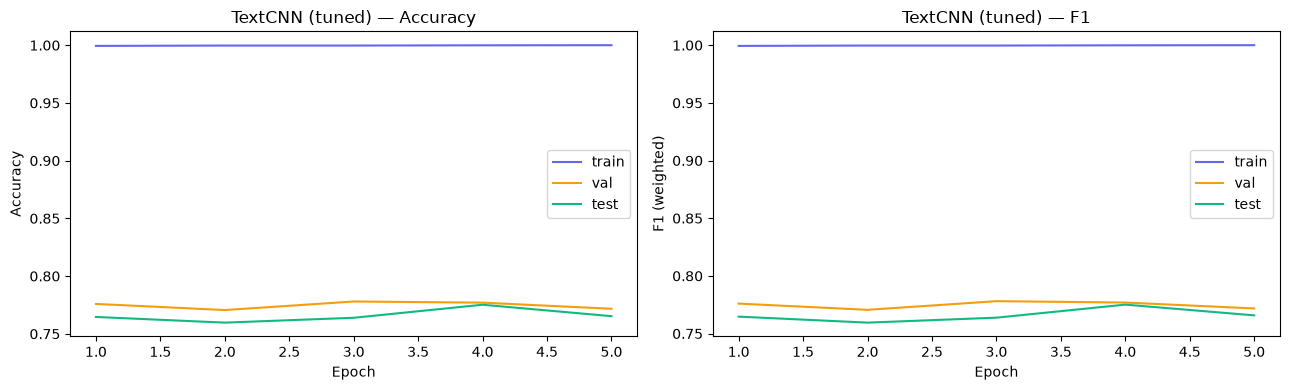

In [13]:
tuned_model = best_overall["model"]
tuned_config = best_overall["config"]
tr_loader, va_loader, te_loader = best_overall["train_loader"], best_overall["val_loader"], best_overall["test_loader"]

FINAL_EPOCHS = 20
FINAL_PATIENCE = 5
FINAL_LR = tuned_config["learning_rate"] * 0.5   # extending training near a good point, not starting cold

optimizer = torch.optim.Adam(tuned_model.parameters(), lr=FINAL_LR, weight_decay=tuned_config["weight_decay"])
criterion = nn.CrossEntropyLoss(weight=class_weights)

best_val_f1 = best_overall["val_f1"]
best_state = {k: v.detach().cpu().clone() for k, v in tuned_model.state_dict().items()}
epochs_no_improve = 0
history = []

print(f"{'Epoch':>6} | {'train_acc':>9} {'train_f1':>9} | {'val_acc':>9} {'val_f1':>9} | {'test_acc':>9} {'test_f1':>9}")
print("-" * 76)
start = time.time()
for epoch in range(1, FINAL_EPOCHS + 1):
    train_one_epoch(tuned_model, tr_loader, optimizer, criterion)

    _, train_metrics, _, _ = evaluate(tuned_model, tr_loader, criterion)
    _, val_metrics, _, _ = evaluate(tuned_model, va_loader, criterion)
    _, test_metrics_ep, _, _ = evaluate(tuned_model, te_loader, criterion)   # informational only
    history.append({
        "epoch": epoch, "train_acc": train_metrics["accuracy"], "train_f1": train_metrics["f1_weighted"],
        "val_acc": val_metrics["accuracy"], "val_f1": val_metrics["f1_weighted"],
        "test_acc": test_metrics_ep["accuracy"], "test_f1": test_metrics_ep["f1_weighted"],
    })

    print(f"{epoch:>6} | {train_metrics['accuracy']:>9.4f} {train_metrics['f1_weighted']:>9.4f} | "
          f"{val_metrics['accuracy']:>9.4f} {val_metrics['f1_weighted']:>9.4f} | "
          f"{test_metrics_ep['accuracy']:>9.4f} {test_metrics_ep['f1_weighted']:>9.4f}")

    if val_metrics["f1_weighted"] > best_val_f1:
        best_val_f1 = val_metrics["f1_weighted"]
        best_state = {k: v.detach().cpu().clone() for k, v in tuned_model.state_dict().items()}
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= FINAL_PATIENCE:
            print(f"\nEarly stopping at epoch {epoch} (best val_f1={best_val_f1:.4f})")
            break

tuned_train_time = time.time() - start
tuned_model.load_state_dict(best_state)
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["epoch"], history_df["train_acc"], label="train", color="#6366f1")
axes[0].plot(history_df["epoch"], history_df["val_acc"], label="val", color="#f59e0b")
axes[0].plot(history_df["epoch"], history_df["test_acc"], label="test", color="#10b981")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].set_title(f"{MODEL_NAME} (tuned) — Accuracy"); axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["train_f1"], label="train", color="#6366f1")
axes[1].plot(history_df["epoch"], history_df["val_f1"], label="val", color="#f59e0b")
axes[1].plot(history_df["epoch"], history_df["test_f1"], label="test", color="#10b981")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("F1 (weighted)"); axes[1].set_title(f"{MODEL_NAME} (tuned) — F1"); axes[1].legend()

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/training_curve_{MODEL_NAME.lower()}_tuned.png", dpi=120, bbox_inches="tight")
plt.show()

In [14]:
# ── final test evaluation with the best checkpoint, and the 90% verdict ──
_, tuned_test_metrics, tuned_test_preds, tuned_test_labels = evaluate(tuned_model, te_loader, criterion)

print(f"{'Model':<24} {'F1 (weighted)':>14} {'Accuracy':>10}")
print("-" * 50)
print(f"{'Baseline (guessed)':<24} {test_metrics['f1_weighted']:>14.4f} {test_metrics['accuracy']:>10.4f}")
print(f"{'Tuned (HPT + full train)':<24} {tuned_test_metrics['f1_weighted']:>14.4f} {tuned_test_metrics['accuracy']:>10.4f}")

final_model, final_variant, final_test_metrics = tuned_model, "HPT_tuned", tuned_test_metrics
n_params = count_parameters(final_model)

print(f"\nFinal model: {MODEL_NAME} ({final_variant})")
print(f"Test accuracy: {final_test_metrics['accuracy']:.4f}  |  Test F1: {final_test_metrics['f1_weighted']:.4f}")
if final_test_metrics["accuracy"] >= 0.90 and final_test_metrics["f1_weighted"] >= 0.90:
    print("\n>>> 90%+ ACHIEVED on both accuracy and F1.")
else:
    print(f"\n>>> Did NOT reach 90%. Best so far: {max(final_test_metrics['accuracy'], test_metrics['accuracy'])*100:.1f}% accuracy.")

print(classification_report(tuned_test_labels, tuned_test_preds, target_names=["positive", "neutral", "negative"]))

mlflow.set_experiment(MLFLOW_EXPERIMENT)
mlflow.start_run(run_name=f"{MODEL_NAME}_HPT_tuned")
loggable_config = {**tuned_config, "kernel_sizes": str(tuned_config["kernel_sizes"]), "final_lr": FINAL_LR}
mlflow.log_params(loggable_config)
for k, v in final_test_metrics.items():
    mlflow.log_metric(f"test_{k}", v)
mlflow.log_metric("train_time_seconds", round(tuned_train_time, 2))
mlflow.log_metric("param_count", n_params)
tuned_cm_path = save_confusion_matrix(tuned_test_labels, tuned_test_preds, f"{MODEL_NAME}_tuned")
mlflow.log_artifact(tuned_cm_path)

Model                     F1 (weighted)   Accuracy
--------------------------------------------------
Baseline (guessed)               0.7408     0.7407
Tuned (HPT + full train)         0.7636     0.7639

Final model: TextCNN (HPT_tuned)
Test accuracy: 0.7639  |  Test F1: 0.7636

>>> Did NOT reach 90%. Best so far: 76.4% accuracy.
              precision    recall  f1-score   support

    positive       0.80      0.76      0.78       503
     neutral       0.71      0.83      0.77       511
    negative       0.80      0.69      0.74       405

    accuracy                           0.76      1419
   macro avg       0.77      0.76      0.76      1419
weighted avg       0.77      0.76      0.76      1419



## 7. Save model + tokenizer for local download

In [15]:
# ── save model + tokenizer for local download ────────────────────
tuned_model_config = {
    "vocab_size": tokenizer.vocab_size_actual, "embed_dim": tuned_config["embed_dim"],
    "num_filters": tuned_config["num_filters"], "kernel_sizes": list(tuned_config["kernel_sizes"]),
    "num_classes": NUM_LABELS, "dropout": tuned_config["dropout"],
}

model_path = os.path.join(MODELS_DIR, "textcnn.pt")
torch.save({
    "model_state_dict": final_model.state_dict(),
    "config": tuned_model_config,
    "test_metrics": final_test_metrics,
    "variant": final_variant,
}, model_path)

tok_path = os.path.join(MODELS_DIR, "tokenizer.pkl")
with open(tok_path, "wb") as f:
    pickle.dump(tokenizer, f)

mlflow.log_artifact(model_path)
mlflow.end_run()

print(f"\nSaved model to: {model_path}")
print(f"Saved tokenizer to: {tok_path}")
print(f"\nDownload these from the Kaggle notebook's Output tab before your session ends:")
print(f"  - {MODELS_DIR}/  (trained model + tokenizer)")
print(f"  - {RESULTS_DIR}/  (confusion matrix, report)")
print(f"  - {os.path.join(BASE_DIR, 'mlflow.db')}  (all MLflow metrics/params — NOT just the mlruns/ folder!)")
print(f"  - {os.path.join(BASE_DIR, 'mlruns')}/  (MLflow artifacts)")


Saved model to: ./saved_models/textcnn.pt
Saved tokenizer to: ./saved_models/tokenizer.pkl

Download these from the Kaggle notebook's Output tab before your session ends:
  - ./saved_models/  (trained model + tokenizer)
  - ./results/  (confusion matrix, report)
  - ./mlflow.db  (all MLflow metrics/params — NOT just the mlruns/ folder!)
  - ./mlruns/  (MLflow artifacts)
